# 10 Decision theory: a probability is not a decision

*Teaching material. Not for clinical use.*

A deployed sepsis model was checked independently on 38,455 hospitalisations, 7% of them with sepsis. It alerted on 18% of all hospitalisations, and it did not identify 67% of the sepsis cases (E-96).

**Before reading on, guess.** Would you switch it on?

- Yes: it still catches a third of sepsis
- No: too many alarms for too little
- It depends on what each kind of mistake costs
- Something else

Write the guess down. It is not marked, and the answer comes in the diagnosis section below.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline
from inference_labs.lenses import bayesian as bayes
from inference_labs.lenses import decision
from inference_labs.lenses import frequentist as freq

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # needs intervention, does not, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()
need = truth["needs_lsi"].to_numpy(bool)
p = freq.probability(observed)

## The idea, before any medicine

Whether to take an umbrella depends on two things: how likely rain is, and what each mistake costs you. Carry it on a dry day and you have lugged it about for nothing. Leave it at home on a wet day and you are soaked. If getting soaked is nine times as bad as carrying it, take it whenever rain is more likely than one in ten. If the two are equally bad, take it only when rain is more likely than not. The forecast is the same; the decision is not.

**Plain.** A probability says how likely something is. A decision also needs to say what each kind of mistake costs, and those costs are a judgement that someone owns. Write the judgement down and the best place for the line follows from it. Change the judgement and the line moves.

**Developer.** With a cost for a miss and a cost for a false alarm, act whenever the probability is at least

```python
threshold = false_alarm_cost / (false_alarm_cost + miss_cost)
expected_cost = (miss_cost * misses + false_alarm_cost * false_alarms) / n
```

Here the probability is lens 02's logistic score for need of a life-saving intervention, the default costs weigh a miss nine times a false alarm, and every cost is a control the reader sets. Computing the expected cost at a hundred thresholds is a hundred counts over the casualties.

**Technical.** Acting at probability $p$ costs $(1-p)\,C_{\mathrm{FP}}$ in expectation and not acting costs $p\,C_{\mathrm{FN}}$, so act when $p \ge t = C_{\mathrm{FP}} / (C_{\mathrm{FP}} + C_{\mathrm{FN}})$. Net benefit judges a model by its consequences at the threshold where one would act (E-93):

$$\mathrm{NB}(t) = \frac{\mathrm{TP}}{n} - \frac{\mathrm{FP}}{n}\,\frac{t}{1-t},$$

compared with treating everyone, $\pi - (1-\pi)\,t/(1-t)$ for prevalence $\pi$, and with treating no one, which scores zero. The threshold encodes how a false positive is weighed against a false negative.

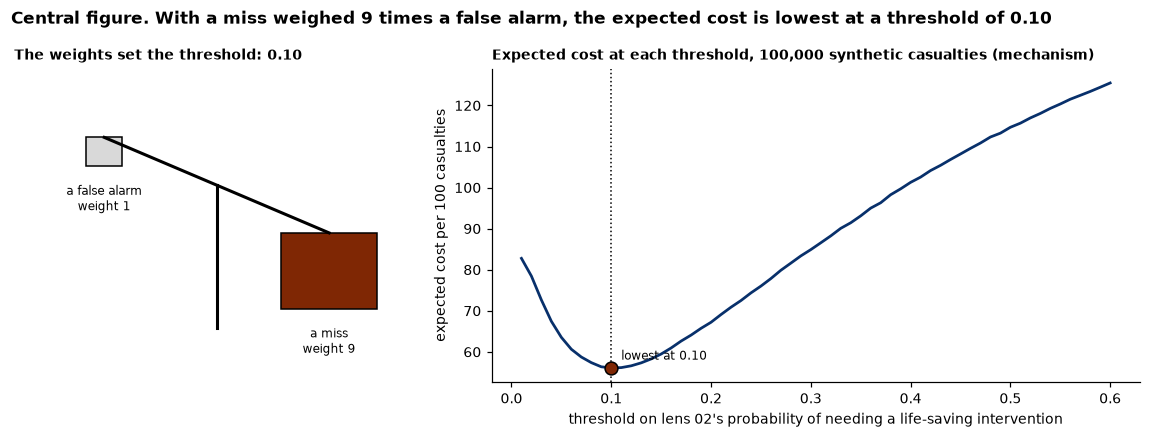

In [2]:
# Central figure: the scales. The controls: change them and run the cell again.
MISS_COST = 9.0          # an assumption: the reader's to set
FALSE_ALARM_COST = 1.0   # an assumption: the reader's to set

costs = {"miss": MISS_COST, "false alarm": FALSE_ALARM_COST}
t_star = decision.threshold(costs)
curve = decision.cost_curve(costs)
best = curve.idxmin()

fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1, 1.6]})
heavier = max(MISS_COST, FALSE_ALARM_COST)
tilt = 0.6 * (MISS_COST - FALSE_ALARM_COST) / heavier
ax.plot([-1, 1], [tilt, -tilt], color="black", linewidth=2)
ax.plot([0, 0], [-1.6, 0], color="black", linewidth=2)
for x, y, w, label, colour in ((-1, tilt, FALSE_ALARM_COST, "a false alarm", LIGHT), (1, -tilt, MISS_COST, "a miss", DARK)):
    size = 0.25 + 0.6 * w / heavier
    ax.add_patch(plt.Rectangle((x - size / 2, y - size), size, size, facecolor=colour, edgecolor="black"))
    ax.text(x, y - size - 0.2, f"{label}\nweight {w:g}", ha="center", va="top", fontsize=8)
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-2.2, 1.3)
ax.axis("off")
ax.set_title(f"The weights set the threshold: {t_star:.2f}", loc="left", fontsize=9)
bx.plot(curve.index, curve.values, color=MID, linewidth=1.8)
bx.axvline(t_star, color="black", linestyle=":", linewidth=1)
bx.scatter(best, curve.min(), s=70, color=DARK, edgecolor="black", zorder=3)
bx.text(best + 0.01, curve.min() + 2, f"lowest at {best:.2f}", fontsize=8)
bx.set_xlabel("threshold on lens 02's probability of needing a life-saving intervention")
bx.set_ylabel("expected cost per 100 casualties")
bx.set_title("Expected cost at each threshold, 100,000 synthetic casualties (mechanism)", loc="left", fontsize=9)
fig.suptitle(f"Central figure. With a miss weighed {MISS_COST / FALSE_ALARM_COST:g} times a false alarm, the expected cost "
             f"is lowest at a threshold of {best:.2f}", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

The weights are the reader's. No source in this repository's register states an exchange rate between a miss and a false alarm, and the default of nine to one is an assumption. Change `MISS_COST` or `FALSE_ALARM_COST` and run the cell again: the lowest point of the curve follows the threshold the weights imply. The curve is computed on synthetic casualties and is a **mechanism**: it shows how the arithmetic works on the generator, not what any real choice costs.

## By hand: ten casualties and three lines

Below are ten synthetic battle casualties, each with lens 02's probability that they need a life-saving intervention and whether, in the generator, they do. A miss costs 9 and a false alarm costs 1, the defaults above. For each of three thresholds, 0.1, 0.3 and 0.5, flag every casualty at or above it, count the misses and false alarms, and add up the cost. Do it on paper before running the next cell.

In [3]:
ids = tuple(observed.loc[observed["stream"] == "battle", "id"].head(10))
ten, totals = decision.by_hand(ids)
print(ten.to_string(index=False))

 id  probability  needs
  2        0.034  False
  4        0.398  False
 10        0.059  False
 13        0.168   True
 15        0.163  False
 17        0.097  False
 20        0.739  False
 27        0.576   True
 30        0.150   True
 35        0.281   True


In [4]:
rows = []
for cut in (0.1, 0.3, 0.5):                         # the same count in plain Python
    misses = sum(1 for prob, n in zip(ten["probability"], ten["needs"]) if n and prob < cut)
    alarms = sum(1 for prob, n in zip(ten["probability"], ten["needs"]) if not n and prob >= cut)
    rows.append({"cut-off": cut, "misses": misses, "false alarms": alarms, "total cost": 9 * misses + 1 * alarms})
hand = pd.DataFrame(rows).set_index("cut-off")
assert (hand.to_numpy() == totals.to_numpy()).all()       # the library agrees with the hand count
hand

,misses,false alarms,total cost
cut-off,,,
0.1,0,3,3
0.3,3,2,29
0.5,3,1,28


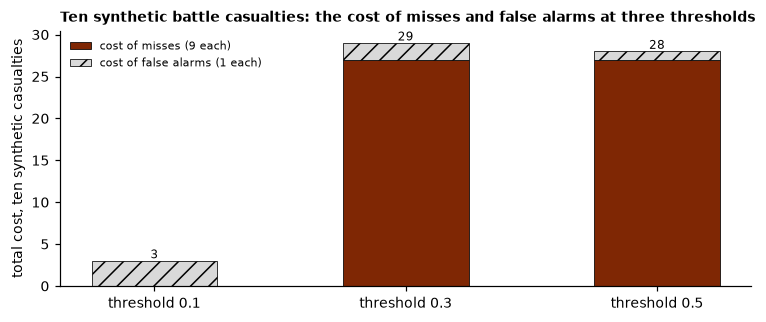

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(hand))
ax.bar(x, 9 * hand["misses"], 0.5, color=DARK, edgecolor="black", linewidth=0.5, label="cost of misses (9 each)")
ax.bar(x, hand["false alarms"], 0.5, bottom=9 * hand["misses"], color=LIGHT, edgecolor="black", linewidth=0.5,
       hatch="//", label="cost of false alarms (1 each)")
for xi, total in zip(x, hand["total cost"]):
    ax.text(xi, total + 0.3, f"{total:g}", ha="center", fontsize=8)
ax.set_xticks(x, [f"threshold {c}" for c in hand.index])
ax.set_ylabel("total cost, ten synthetic casualties")
ax.legend(fontsize=7, frameon=False)
ax.set_title("Ten synthetic battle casualties: the cost of misses and false alarms at three thresholds", loc="left",
             fontsize=9)
plt.tight_layout()
plt.show()

That is all a decision rule is: for each threshold, misses times their cost plus false alarms times theirs. Written as notation, with $\mathrm{FN}(t)$ misses and $\mathrm{FP}(t)$ false alarms at threshold $t$,

$$\mathrm{cost}(t) = C_{\mathrm{FN}}\,\mathrm{FN}(t) + C_{\mathrm{FP}}\,\mathrm{FP}(t),$$

and the threshold with the lowest cost, on average over many casualties, is $C_{\mathrm{FP}} / (C_{\mathrm{FP}} + C_{\mathrm{FN}})$.

## Diagnosis: where to set the triage line

**The answer to the hook.** The sepsis model's area under the curve was 0.63 (E-96). Whether to switch it on cannot be read from that, or from its alert rate or its misses alone: it depends on what an alert costs staff and what a missed case costs a patient, which the register's row does not give. Net benefit is the tool for asking it at the threshold where one would act (E-93).

On the generator the question can be asked of every method built so far. The curves below give net benefit per 100 casualties across thresholds for lens 02's logistic score, lens 04's single tree and forest, the MPTT-24 under the reading of its published figure and under the text reading labelled as validated (D-24), treating everyone and treating no one. A rule gives one flag whatever the threshold, so its net benefit changes only through the weight $t/(1-t)$. Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the Joint Theatre Trauma Registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).

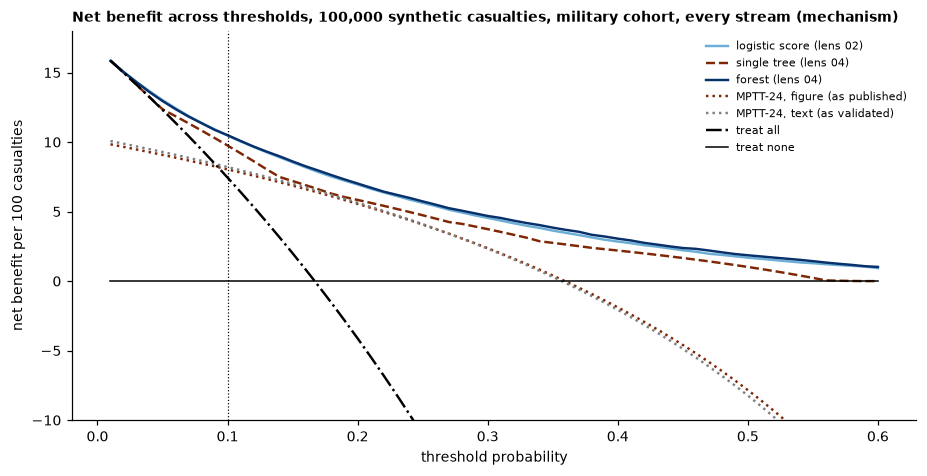

,logistic score (lens 02),single tree (lens 04),forest (lens 04),"MPTT-24, figure (as published)","MPTT-24, text (as validated)",treat all,treat none
threshold,,,,,,,
0.05,13.02,12.36,12.95,9.08,9.29,12.32,0.0
0.10,10.47,9.75,10.50,8.04,8.21,7.45,0.0
0.20,6.95,5.84,7.02,5.56,5.64,-4.12,0.0
0.30,4.55,3.74,4.69,2.37,2.34,-18.99,0.0


In [6]:
nb = decision.net_benefit_table()
styles = {"logistic score (lens 02)": (PALE, "-"), "single tree (lens 04)": (DARK, "--"), "forest (lens 04)": (MID, "-"),
          "MPTT-24, figure (as published)": (DARK, ":"), "MPTT-24, text (as validated)": ("grey", ":"),
          "treat all": ("black", "-."), "treat none": ("black", "-")}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for name, (colour, style) in styles.items():
    ax.plot(nb.index, nb[name], style, color=colour, linewidth=1.6 if name != "treat none" else 1, label=name)
ax.axvline(decision.threshold(), color="black", linestyle=":", linewidth=0.8)
ax.set_ylim(-10, 18)
ax.set_xlabel("threshold probability")
ax.set_ylabel("net benefit per 100 casualties")
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title("Net benefit across thresholds, 100,000 synthetic casualties, military cohort, every stream (mechanism)",
             loc="left", fontsize=9)
plt.tight_layout()
plt.show()
nb.loc[[0.05, 0.1, 0.2, 0.3]].round(2)

### The line as one point among several

The same trade can be drawn as under-triage against over-triage. The sources do not all mean the same thing by over-triage. The MPTT-24's authors define under-triage as 1 minus sensitivity and over-triage as 1 minus the positive predictive value (E-12). A simulation of a mass casualty incident defines over-triage as the share of non-critical patients among those labelled critical (E-125). For the Dutch protocol and practice (E-88), the benchmark (E-87) and London 2005 (E-126), the register gives no definition.

- The MPTT-24 and the Military Sieve, as published in the military registry (E-09, E-10), with the Sieve's over-triage calculated here from its sensitivity, specificity and the registry's share in Priority 1.
- A review of 21 studies of field triage protocols cites benchmarks of under-triage below 5% and over-triage below 50% (E-87). It is drawn as one region among others, not as a standard the military rule should meet.
- In ten Dutch hospitals the protocol alone would have given under-triage of 63.8% and over-triage of 7.4%; in practice they were 21.6% and 30.6% (E-88).
- In London on 7 July 2005, scene over-triage was 64%: 82% at the two sites triaged by ambulance staff and bystanders and 33% at the two triaged mainly by advanced prehospital teams. Critical mortality was 15%, which the authors judge unrelated to over-triage (E-126). The register gives no under-triage for it, so it is drawn as over-triage only.
- On the generator, the MPTT-24 and lens 02's score at the reader's costs, with E-12's definitions (mechanism).

In [7]:
points = decision.operating_points(costs)
points.round(3)

,under-triage,over-triage,source,over-triage defined as
point,,,,
"MPTT-24, military registry",0.333,0.330,"E-09, E-12",1 minus PPV (E-12)
"MPTT-24, civilian registry",0.465,0.660,"E-09, E-12",1 minus PPV (E-12)
"Military Sieve, military registry",0.568,0.138,"E-09, E-10, E-12","1 minus PPV, calculated here"
Dutch protocol alone,0.638,0.074,E-88,not given in the register
Dutch practice,0.216,0.306,E-88,not given in the register
"MPTT-24, figure (as published), on the generator",0.400,0.641,mechanism,1 minus PPV (E-12)
"MPTT-24, text (as validated), on the generator",0.386,0.643,mechanism,1 minus PPV (E-12)
"logistic score at the reader's costs, on the generator",0.135,0.713,mechanism,1 minus PPV (E-12)


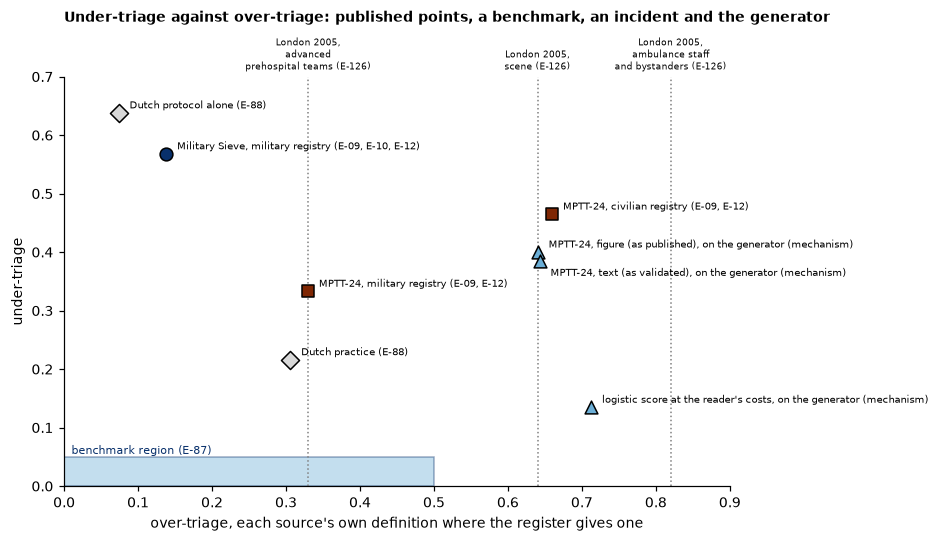

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5))
b = decision.BENCHMARK
ax.add_patch(plt.Rectangle((0, 0), b["over-triage below"], b["under-triage below"], facecolor=PALE, alpha=0.4,
                           edgecolor=MID))
ax.text(0.01, 0.055, "benchmark region (E-87)", fontsize=7, color=MID)
markers = {"E-09, E-12": ("s", DARK), "E-09, E-10, E-12": ("o", MID), "E-88": ("D", LIGHT), "mechanism": ("^", PALE)}
for name, row in points.iterrows():
    marker, colour = markers[row["source"]]
    ax.scatter(row["over-triage"], row["under-triage"], s=70, marker=marker, color=colour, edgecolor="black", zorder=3)
    below = name.startswith("MPTT-24, text")
    ax.annotate(f"{name} ({row['source']})", (row["over-triage"], row["under-triage"]), fontsize=6.5,
                xytext=(7, -10 if below else 3), textcoords="offset points")
london = {"scene": "scene", "ambulance staff and bystanders": "ambulance staff\nand bystanders",
          "advanced prehospital teams": "advanced\nprehospital teams"}
for label, x in decision.LONDON.items():
    ax.axvline(x, color="grey", linestyle=":", linewidth=1)
    ax.text(x, 1.01, f"London 2005,\n{london[label]} (E-126)", fontsize=6, ha="center", va="bottom",
            transform=ax.get_xaxis_transform())
ax.set_xlim(0, 0.9)
ax.set_ylim(0, 0.7)
ax.set_xlabel("over-triage, each source's own definition where the register gives one")
ax.set_ylabel("under-triage")
ax.set_title("Under-triage against over-triage: published points, a benchmark, an incident and the generator", loc="left",
             fontsize=9, pad=36)
plt.tight_layout()
plt.show()

### When the system is full

In a simulation of a mass casualty incident, over-triage raised, lowered or left critical mortality unchanged depending on what caused it, and the ratio of critical patients to treatment capability mattered more than the over-triage level in every scenario (E-125). The cost of a false alarm is not a constant.

The generator can show the mechanism, on assumed costs. Suppose each casualty flagged beyond what the system can handle adds a further cost of 3, an assumption. As capacity per 100 casualties falls, false alarms crowd out the casualties who need the slots, and the best threshold moves up. This is a mechanism demonstration on assumed costs, not a finding about any real system.

,best threshold,flagged per 100,cost per 100
capacity per 100,,,
60,0.10,50.31,56.10
50,0.11,47.10,56.18
40,0.14,38.61,58.29
30,0.19,28.97,65.74
25,0.22,24.75,70.88
20,0.26,20.34,78.88
15,0.32,15.36,89.33
10,0.37,12.27,103.13


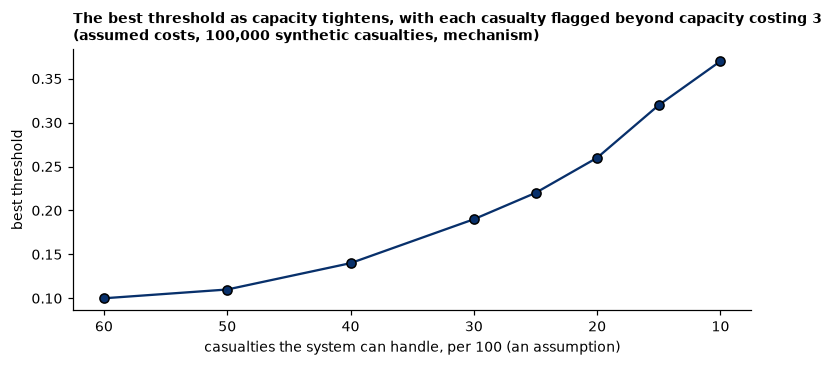

In [9]:
shift = decision.load_shift()
display(shift.round(2))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(shift.index, shift["best threshold"], "o-", color=MID, markeredgecolor="black")
ax.invert_xaxis()
ax.set_xlabel("casualties the system can handle, per 100 (an assumption)")
ax.set_ylabel("best threshold")
ax.set_title("The best threshold as capacity tightens, with each casualty flagged beyond capacity costing 3\n"
             "(assumed costs, 100,000 synthetic casualties, mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## Treatment: hold or fly, and two casualties for one aircraft

This section is about treatment decisions, and its results are kept apart from the diagnosis results above.

Take haemorrhage casualty 64 from the walk-through page, a synthetic battle casualty whose scan before hospital showed free fluid. Take lens 03's belief that they are bleeding into the abdomen, after the scan, and the generator's chance that a casualty bleeding significantly dies from bleeding by a given time. That chance comes from the hazard fitted to the three hourly rates of E-85, which were measured from hospital admission and run here from injury, an assumption the generator makes. Surgery on arrival is taken to stop a bleeding death, and the flight is taken to last 30 minutes: both assumptions. The expected chance of dying before arrival is the belief times the chance of a bleeding death by the time of arrival, and every minute held here adds to it.

haemorrhage casualty 64: belief after the scan 46.9%, 49 minutes since injury


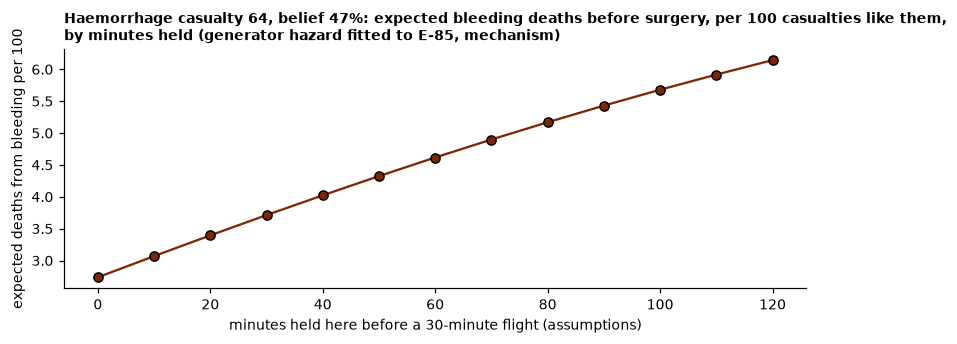

In [10]:
walk = bayes.walkthrough("haemorrhage", "pre_hospital", None, 64)
belief = float(walk.line["evacuation"].mean())
now = float(walk.record["t_phec_min"])
hold = decision.hold_curve(belief, now)
print(f"haemorrhage casualty 64: belief after the scan {belief:.1%}, {now:.0f} minutes since injury")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(hold.index, hold.values, "o-", color=DARK, markeredgecolor="black")
ax.set_xlabel("minutes held here before a 30-minute flight (assumptions)")
ax.set_ylabel("expected deaths from bleeding per 100")
ax.set_title(f"Haemorrhage casualty 64, belief {belief:.0%}: expected bleeding deaths before surgery, per 100 casualties like "
             f"them,\nby minutes held (generator hazard fitted to E-85, mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

Now one aircraft and two casualties: haemorrhage casualty 1, whose scan before hospital showed no free fluid, and casualty 64 from above, injured later and with a positive scan. Whoever flies second waits a round trip, three flights in all. The order that gives fewer expected bleeding deaths flies first. The beliefs are carried as draws (D-19), so the comparison carries its uncertainty: the share of draws in which flying casualty 64 first is better.

In [11]:
pair = []
for k in (64, 1):
    w = bayes.walkthrough("haemorrhage", "pre_hospital", None, k)
    pair.append(decision.Casualty(f"casualty {k}", w.line["evacuation"], float(w.record["t_phec_min"])))
    print(f"haemorrhage casualty {k}: belief {w.line['evacuation'].mean():.1%}, {w.record['t_phec_min']:.0f} minutes since injury")
orders = decision.aircraft(*pair)
for name, value in orders.items():
    name = name.replace("the first order", "flying casualty 64 first")
    print(f"{name}: " + (f"{value:.1%}" if isinstance(value, float) else
                         f"expected bleeding deaths {value.mean():.4f} ({value.interval()[0]:.4f} to {value.interval()[1]:.4f})"))

haemorrhage casualty 64: belief 46.9%, 49 minutes since injury
haemorrhage casualty 1: belief 8.1%, 40 minutes since injury
casualty 64 first: expected bleeding deaths 0.0349 (0.0251 to 0.0461)
casualty 1 first: expected bleeding deaths 0.0503 (0.0334 to 0.0697)
chance flying casualty 64 first is better: 100.0%


,scan before hospital,scan in hospital
belief and clock,2.098,1.927
"MPTT-24 priority, then the longer wait",2.185,2.185
chance,2.259,2.259
knowing who is bleeding,1.821,1.821


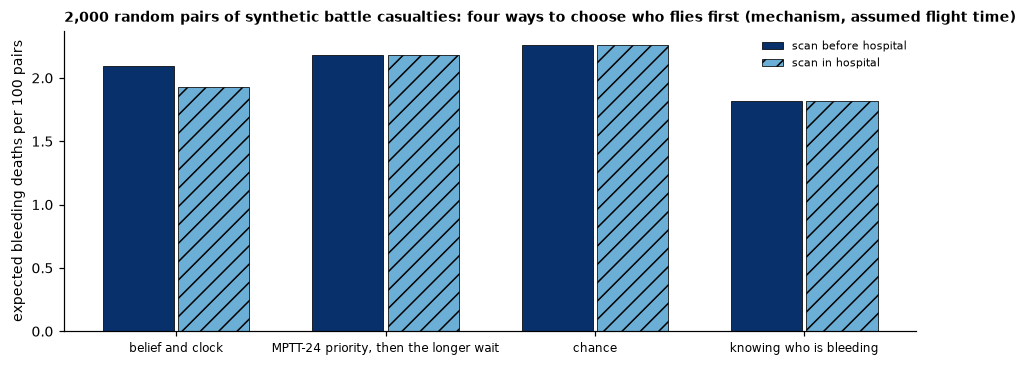

In [12]:
policy = pd.DataFrame({baseline.SETTING_NAMES[s]: decision.aircraft_policy(s) for s in decision.SETTINGS}).drop("pairs")
display(policy.round(3))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
names = list(policy.index)
x = np.arange(len(names))
for j, (setting, colour, hatch) in enumerate(((policy.columns[0], MID, ""), (policy.columns[1], PALE, "//"))):
    ax.bar(x + (j - 0.5) * 0.36, policy[setting], 0.34, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5,
           label=setting)
ax.set_xticks(x, names, fontsize=8)
ax.set_ylabel("expected bleeding deaths per 100 pairs")
ax.legend(fontsize=7, frameon=False)
ax.set_title(f"{decision.aircraft_policy()['pairs']:,} random pairs of synthetic battle casualties: four ways to choose who flies first "
             "(mechanism, assumed flight time)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## The failure: optimising accuracy and losing the torso bleeds

Among the injuries of UK Service personnel admitted in Afghanistan under a trauma team, extremities make up 44% of 10,371 injuries and the torso 7% (E-37, E-38). In US battlefield deaths from 2001 to 2011 (E-39), the site of lethal haemorrhage was truncal in 67.3%, junctional in 19.2% and extremity in 13.5% (E-41). The two figures come from different populations, so they are set side by side as a contrast, not combined. The injuries seen most often are not the bleeding that kills most often. A classifier tuned for overall accuracy treats every miss alike, and so it can be at its most accurate while missing the casualties most likely to die.

On the generator, lens 04's treatment tree gives each battle casualty a probability of bleeding significantly. Cut it where overall accuracy is highest, then where the cost is lowest once each missed bleeder is weighed by their chance of a bleeding death, at the default costs. The generator sets each site's chance of a bleeding death so that its deaths from bleeding split by site as in E-41.

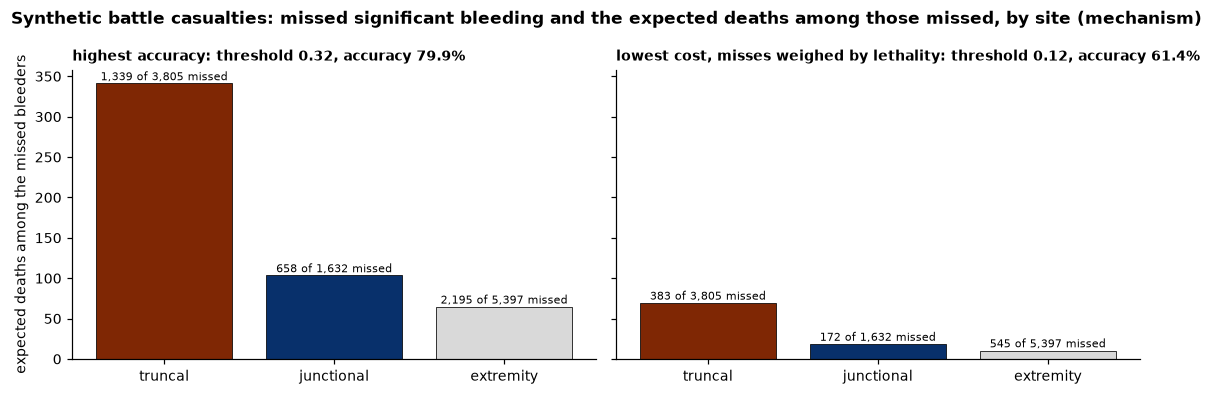

In [13]:
fail = decision.torso_failure()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for ax, (name, r) in zip(axes, fail.items()):
    site = r["by site"]
    ax.bar(site.index, site["expected deaths among the missed"], color=[DARK, MID, LIGHT], edgecolor="black", linewidth=0.5)
    for i, (s, row) in enumerate(site.iterrows()):
        ax.text(i, row["expected deaths among the missed"] + 4, f"{int(row['missed']):,} of {int(row['bleeding']):,} missed",
                ha="center", fontsize=7)
    ax.set_title(f"{name}: threshold {r['threshold']:.2f}, accuracy {r['accuracy']:.1%}", loc="left", fontsize=9)
axes[0].set_ylabel("expected deaths among the missed bleeders")
fig.suptitle("Synthetic battle casualties: missed significant bleeding and the expected deaths among those missed, by site "
             "(mechanism)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label. Axes 3, 4 and 5 are stated. Axis 7, the value of the decision, is the subject of this lens and is now computed for every lens built so far.

The diagnosis column is lens 02's probability turned into a decision at the threshold the default costs set, scored on all 100,000 synthetic casualties of the military cohort, every stream. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24). Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the Joint Theatre Trauma Registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The treatment column is the choice of who flies first, scored by expected bleeding deaths over random pairs of battle casualties. Fit is weak for diagnosis, where this lens only applies costs to another lens's probability, and native for treatment, where allocating one aircraft is a decision this lens exists to make.

In [14]:
decision.seven_axes()

,diagnosis: decision on lens 02's score,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)","treatment: one aircraft, two casualties"
axis,,,,
1 Discrimination (mechanism),"sensitivity 86.5%, specificity 57.0% at the cost threshold 0.10; all 100,000 synthetic casualties of the military cohort, disease included","sensitivity 60.0%, specificity 78.6%","sensitivity 61.4%, specificity 77.8%","Not a classifier: expected bleeding deaths per 100 pairs 2.10, against 2.18 by the MPTT-24's priority and 2.26 by chance; 1.82 if it were known who is bleed..."
2 Calibration (mechanism),expected cost 56.1 per 100 at the stated costs; the probability it acts on has calibration +0.001,expected cost 78.0 per 100 at the stated costs,expected cost 76.5 per 100 at the stated costs,Not applicable
3 Uncertainty expressed,"None in the decision; the costs are stated, not estimated",None: a priority,None: a priority,The belief behind each casualty is a distribution (lens 03)
4 What it needed,Lens 02's probability and two stated costs (assumptions),Rules only (E-08),Rules only (E-08),"Lens 03's belief, the generator's bleeding hazard (E-85) and a stated flight time"
5 Readability,One comparison: is the probability above the threshold the costs set?,Six yes-or-no steps,Six yes-or-no steps,"Two sums of two products, compared"
"6 Robustness, setting changed (mechanism)","Scan in hospital: sensitivity 86.5%, specificity 57.0%, unchanged because in the generator the setting changes only the scan",Unchanged,Unchanged,"Scan in hospital: 1.93 against 2.18 per 100 pairs, the belief being sharper after an in-hospital scan"
7 Decision value,"Net benefit 10.5 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism)","Net benefit 8.0 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism)","Net benefit 8.2 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism)",Expected deaths are the decision value here: see axis 1


In [15]:
card = pd.DataFrame([vars(row) for row in decision.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan before hospital",0.865,0.600,mechanism,weak,generator
1,diagnosis,"specificity, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan before hospital",0.570,0.786,mechanism,weak,generator
2,diagnosis,"expected cost per 100, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan before hospital",56.105,78.007,mechanism,weak,generator
3,diagnosis,"net benefit per 100, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan before hospital",10.470,8.037,mechanism,weak,generator
4,diagnosis,"sensitivity, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan in hospital",0.865,0.600,mechanism,weak,generator
5,diagnosis,"specificity, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan in hospital",0.570,0.786,mechanism,weak,generator
6,diagnosis,"expected cost per 100, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan in hospital",56.105,78.007,mechanism,weak,generator
7,diagnosis,"net benefit per 100, lens 02's score at the cost threshold 0.10 against need for a life-saving intervention, scan in hospital",10.470,8.037,mechanism,weak,generator
8,treatment,"expected bleeding deaths per 100 pairs, one aircraft, belief and clock against MPTT-24 priority, battle casualties, scan before hospital",2.098,2.185,mechanism,native,generator
9,treatment,"expected bleeding deaths per 100 pairs, one aircraft, belief and clock against MPTT-24 priority, battle casualties, scan in hospital",1.927,2.185,mechanism,native,generator


Two rows carry the lesson. At the default costs the decision accepts many more false alarms than the rule to miss far fewer of those in need, and its expected cost is lower because the costs say a miss matters more; at other costs the comparison could reverse. And with one aircraft, ordering by belief and clock gives fewer expected bleeding deaths than ordering by the rule's priority, on synthetic casualties and under assumed times.

**Teach back.** In one sentence, why can two people agree on a casualty's probability and still disagree about what to do?

## The brain analogy, and where it breaks

**What it resembles.** Value-based choice: weighing what each outcome is worth and choosing the option with the most to gain. A medic who sends a borderline casualty forward because a miss would be catastrophic is weighing costs, whether or not the costs are written down.

**Where it breaks.** Stated utilities are not how people choose. People do not hold a fixed exchange rate between a miss and a false alarm; they shift it with fatigue, with what happened last time and with how full the system feels. Decision theory says what follows from a stated judgement. It does not say how anyone arrives at the judgement, or whose it should be.